# Descente de gradient et différenciation automatique avec PyTorch

Nous allons utiliser ``PyTorch`` et ses outils de différenciation automatique pour trouver les paramètres optimaux d'une fonction linéaire. On va notamment utiliser une descente de gradient (bien que, dans le cas très simple que nous allons utiliser, une forme close de la solution existe !).

Nous allons commencer par importer / télécharger la librairie pytorch (le plus simple étant probablement de travailler sur Google Colab si vous n'arrivez pas à l'installer).

In [420]:
import torch

Cette librairie utilise une structure de données spécifique : les ``Tensor`` qui sont une extension des matrices à plus de 2 dimensions (même si on peut définir des tenseurs de dimension 1 ou 2). Par exemple, l'instruction suivante permet de créer un tenseur en dimension 1, puis un tenseur en dimension 2, puis dimension 3. La syntaxe est similaire à celle de ``numpy`` : nous l'apprendrons au fur et à mesure des séances.

In [421]:
x = torch.tensor([1, 2, 3])
print(x, x.shape, type(x))
x = torch.tensor([[1, 2, 3], [2, 5, 8]])
print(x, x.shape, type(x))
x = torch.tensor([[[1, 2, 3], [2, 5, 8]], [[10, 12, 13], [22, 54, 102]]])
print(x, x.shape, type(x))

tensor([1., 2., 3.]) torch.Size([3]) <class 'torch.Tensor'>
tensor([[1., 2., 3.],
        [2., 5., 8.]]) torch.Size([2, 3]) <class 'torch.Tensor'>
tensor([[[  1.,   2.,   3.],
         [  2.,   5.,   8.]],

        [[ 10.,  12.,  13.],
         [ 22.,  54., 102.]]]) torch.Size([2, 2, 3]) <class 'torch.Tensor'>


## Génération de données

Nous allons commencer par générer des données (bruitées) selon le modèle $y = 2x + 1$. 

In [422]:
import matplotlib.pyplot as plt #pour les graphiques

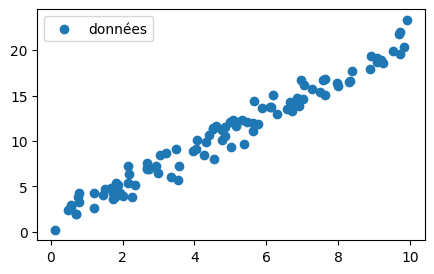

In [423]:
torch.manual_seed(2024) 
#on commence par stocker les vrais paramètres
w = torch.tensor([2., 1.])
#on génère des samples x
n = 100 #on tire 100 points
x = torch.ones(n,2) # matrice x de taille n x 2
x[:,0] = torch.rand(n) * 10  #la première colonne correpond à des valeurs uniformes dans [0, 10]
#et des labels y bruités
bruit = torch.randn(n) #on génére des bruits qui suivent une loi normale
y = torch.matmul(x, w) + bruit #et on calcule y = w*x + bruit

plt.figure(figsize=(5, 3))
plt.scatter(x[:,0], y, label='données')
plt.legend()
plt.show()

## Définition du problème, de fonctions utiles et initialisation des paramètres

On va définir une fonction ``mse`` ( = mean square error = moyenne des écarts au carré) qui calcule l'erreur moyenne au carré entre la prédiction et les observations (stockées dans des vecteurs ``y_true`` et ``y_pred``). 

<div class="admonition note">
<p class="admonition-title"></p>
Complétez le code suivant pour que l'on calcule l'erreur moyenne au carré. 
</div>

In [424]:
def mse(y_true, y_pred):
    return  #à compléter

L'objectif est, étant donné les observations, de pouvoir retrouver les vrais paramètres $w$ à l'aide des données. On veut donc résoudre, en choisissant une loss mse :
$$ \hat{W}^\star = \arg \min_{w} \frac{1}{n} \| XW - Y \|^2.$$
Cette écriture matricielle est équivalente à écrire 
$$ \hat{W}^\star = \arg \min_{W} \frac{1}{n} \sum_i \ell(x_i W, y_i) = \arg \min_{W} \frac{1}{n} \sum_i (\hat{y}_i- y_i)^2$$

Dans la réalité, il existe une forme close pour trouver une estimation $\hat{W}^\star$ : $\hat{W}^\star = X^\dagger Y$, où $X^\dagger$ est la pseudo inverse de $X$ (que l'on peut calculer avec `torch` grâce à l'instruction `torch.linalg.pinv`)

In [ ]:
w_hat = torch.linalg.pinv(x).matmul(y)
print(w_hat)

Pour ce premier exemple, au lieu d'utiliser cette forme close, on va plutôt choisir de faire une descente de gradient pour estimer les paramètres $w$. 
<div class="admonition note">
<p class="admonition-title"></p>
Calculer le gradient par rapport à $w$ de la fonction $\frac{1}{n}\| XW - Y \|^2$
</div>

## Descente de gradient

### Algorithme

L'algorithme de descente de gradient part d'une solution initiale $w_0$ et itérativement calcule des estimations $w_{s+1}$ en utilisant l'estimation à l'étape $s$, son gradient et un pas de descente $\eta$ : 
$$w_{s+1} = w_{s} - \eta \nabla_w f(w_s)$$

où $f(w) = \frac{1}{n}\| Xw - y \|^2$.

<div class="admonition note">
<p class="admonition-title"></p>
Complétez le code suivant en intégrant votre calcul de gradient. 
</div>

In [ ]:
w_opt = torch.tensor([0.,0.]) #point de départ, w_0
loss = mse(torch.matmul(x, w_opt), y) # et la loss associée
l_loss = [loss] # on stocke la loss dans une liste
lr = 0.01 # learning rate
for i in range(20): # 20 itérations de descente de gradient
    grad = # implémentez le gradient ici
    w_opt = w_opt - lr*grad
    loss = mse(torch.matmul(x, w_opt), y)
    l_loss.append(loss) # on garde en mémoire l'évolution de la loss

plt.figure(figsize=(5, 3))
plt.plot(l_loss)
plt.show()

On voit que la loss diminue au cours des itérations jusqu'à **converger** vers une valeur proche de 0 (ce qui signifie que $X\hat{w}^\star$ est proche de $y$). A la fin des itérations, l'estimation de $w$ est 

In [ ]:
w_opt

Et les données selon le modèle ajusté sont les suivantes :

In [ ]:
plt.figure(figsize=(5, 3))
plt.scatter(x[:,0], y, label='données')
data = torch.matmul(x, w_opt) #y chapeau = X.W_opt
plt.scatter(x[:,0], data, label="predictions")
plt.legend()
plt.show()

On voit que nos estimations ne sont pas loin des vraies données !

### Influence de l'hyperparamètre correspondant au pas de descente (``lr``) et du nombre d'itérations. Influence de l'initialisation.

<div class="admonition note">
<p class="admonition-title"></p>
Jouez avec le code précédent et changez le ``learning rate`` ainsi que le nombre d'itérations. Que peut-on conclure ?

Jouez également avec le point de départ (on l'a fixé à $[0, 0]$ de façon arbitraire) : est ce que cela a un impact sur la qualité de l'estimation ? A votre avis, pourquoi ?
</div>

## Pytorch : une librairie pour faire de la différenciation automatique

### Retour sur notre exemple de régression linéaire

Pour notre modèle linéaire simple, on a dû calculer le gradient à la main. Parfois, ce travail peut être un peu fastidieux... mais assez facile à faire grâce à la propriété de chain rule du calcul du gradient qui permet de sérialiser les calculs. Pytorch implémente des outils de différenciation automatique : si tous les élements sont des Tensor, on va pouvoir calculer le gradient automatiquement.
Pour cela, on va devoir spécifier sur quels tenseurs on souhaite calculer le gradient, grâce à l'instruction ``requires_grad=True``:

In [242]:
w_opt_auto = torch.tensor([0.,0.], requires_grad= True) 

Cette instruction permet de spécifier que ``w_opt_auto`` est un Tensor que l'on va chercher à optimiser. On va également indiquer que l'on va utiliser une loss type ``mse``, c'est à dire une "mean square error", qui correspond à celle que l'on a implémenté au début. Pytorch a sa propre implémentation de cette fonction de loss :

In [243]:
loss = torch.nn.MSELoss()

L'instruction ``.grad`` permet de récupérer la valeur du gradient, et l'instruction ``.backward`` de le calculer. On peut ainsi réécrire une partie de la boucle précédente sans calculer explicitement le gradient :

In [ ]:
lr = 0.01
for i in range(20):
    pred = loss(torch.matmul(x, w_opt_auto), y)
    pred.backward()
    with torch.no_grad(): # la mise à jour de W ne doit pas être suivie par autograd
        w_opt_auto = (w_opt_auto - lr * w_opt_auto.grad).requires_grad_(True)  # nouveau tenseur-feuille : .grad repart à zéro
w_opt_auto

L'avantage ici est que l'on n'a pas eu besoin de définir explicitement le gradient, ni de coder la loss associée (on a appelé une ``MSELoss``). On peut même faire encore mieux ! On peut ne pas avoir à définir la mise à jour des paramètres ``w_opt_auto`` en fonction du ``lr`` et de la valeur du gradient. Pour cela, on va définir un ``optimizer`` qui va prendre en paramètre le ``lr`` et un ``model``. On choisit ici un ``SGD`` (``GD`` signifiant gradient descent, on pourra discuter du ``S`` plus tard).

On commence dans un premier temps par créer un modèle, c'est à dire la fonction que l'on utilise (une simple régression linéaire ici). On parlera d'**architecture** quand on utilisera un modèle d'apprentissage profond. La première fonction ``init`` permet de définir les paramètres du modèle et la fonction ``forward`` permet de calculer la valeur de $\hat{y}$ étant donné $\hat{w}$ et $x$ :


In [345]:
class regression_lineaire_2d(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = torch.nn.Parameter(torch.zeros(2)) #poids initialisés à [0,0]

    def forward(self, x):
        return torch.matmul(x, self.weights)   


On va pouvoir maintenant définir notre ``optimizer``, qui va faire une descente de gradient sur nos ``model.parameters``, c'est-à-dire les poids ``weights``. On choisit un ``lr`` de 0.01 :

In [307]:
model = regression_lineaire_2d()
loss = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

Et on peut ensuite écrire notre descente de gradient :

In [ ]:
l_loss = []
for i in range(20):
    optimizer.zero_grad() # on "vide" les gradients pour éviter qu'ils s'accumulent
    y_hat = model(x) #calcule la prédiction 
    pred = loss(y_hat, y) #calcule la loss
    pred.backward() #calcule le gradient
    optimizer.step() #on fait un pas de descente de gradient
    l_loss.append(pred.item())
plt.figure(figsize=(5, 3))
plt.plot(l_loss)
plt.show()
print(model.weights)

### Un autre exemple : un modèle **non convexe** et impact de l'initialisation

On considère maintenant un modèle **vraiment non convexe** : un **neurone unique**,
$$\hat{y} = w_2 \, \tanh(w_1 x).$$
Cette fois, le paramètre $w_1$ est **à l'intérieur** de la fonction $\tanh$ : la loss n'est plus quadratique en $(w_1, w_2)$ et possède de **vrais minima locaux**. (C'est aussi la **brique de base** du perceptron / des réseaux de neurones, que l'on verra au CM5.)

In [ ]:
torch.manual_seed(2024)
# vrais paramètres du neurone
w1_true, w2_true = 1.5, 3.0
n = 100
x = torch.rand(n) * 6 - 3            # x dans [-3, 3]
bruit = 0.1 * torch.randn(n)
y = w2_true * torch.tanh(w1_true * x) + bruit

plt.figure(figsize=(5, 3))
plt.scatter(x, y, label='données')
plt.legend()
plt.show()

On définit le modèle comme un `torch.nn.Module`, avec **deux paramètres** $w_1$ et $w_2$.

<div class="admonition note">
<p class="admonition-title"></p>

Complétez le modèle `neurone` : le paramètre `w2` et la fonction `forward` (qui renvoie $w_2 \tanh(w_1 x)$). Initialisez `w1` et `w2` à `0.5`.

</div>

In [ ]:
class neurone(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.w1 = torch.nn.Parameter(torch.tensor([0.5]))
        self.w2 = ...    # à compléter

    def forward(self, x):
        return ...       # à compléter : w2 * tanh(w1 * x)

<div class="admonition note">
<p class="admonition-title"></p>

Estimez $(w_1, w_2)$ par descente de gradient (reprenez la boucle avec un `optimizer` ; `lr = 0.05` et ~200 itérations conviennent). Affichez la courbe de loss, les paramètres estimés, et superposez le modèle ajusté aux données.

</div>

<div class="admonition note">
<p class="admonition-title"></p>

Refaites la descente en **initialisant** cette fois `w1 = -0.5` et `w2 = -0.5`. Comparez : que valent les paramètres estimés ? La loss finale est-elle la même ? Et la **fonction ajustée** ? Pourquoi l'initialisation change-t-elle le résultat ici, alors qu'elle ne le changeait pas pour la régression linéaire ?

</div>

<div class="admonition attention">
Ce qu'on a vu dans cette partie : 

- ``pytorch`` permet de faire de la différenciation automatique

- un ``model`` permet de définir les paramètres (dans la fonction ``init``) et l'équation du modèle (dans la fonction ``forward``)

- un ``optimizer`` prend en paramètre les paramètres du modèle (``model.parameters()``) et un ``lr`` : il permet de faire une descente de gradient avec l'instruction ``optimizer.step()``

- une ``loss`` (par exemple ``MSELoss``) permet de définir la loss que l'on va minimiser. On peut utiliser la méthode ``.backward()`` sur son instanciation lorsque l'on veut faire une itération de l'algorithme d'optimisation

- les gradient s'accumulent ! Il faut penser à les remettre à 0 avec ``optimizer.zero_grad()`` à chaque itération de l'algorithme

- pour un modèle **non convexe** (comme le neurone), l'initialisation peut mener à des **minima différents** : elle compte vraiment

- le résultat est dépendant de i) l'initialisation des paramètres ii) le learning rate iii) le nombre d'itérations de l'algorithme

- lorsque l'on utilise une descente de gradient, il faut bien vérifier le graphique de décroissance de la loss pour s'assurer que l'algorithme a bien **convergé**.
</div>